# 🩺 Skin Lesion Classification: Melanoma vs. Benign

## ISIC 2020 — CNN vs. RNN vs. Vision Transformer

This Jupyter Notebook is designed to run **top-to-bottom** for an educational machine-learning project.

### Models compared
- **CNN:** EfficientNetB0
- **RNN:** CNN feature extractor + Bidirectional LSTM
- **Transformer:** Vision Transformer-style patch + Transformer encoder

### Output
The notebook produces:
- EDA and class distribution
- Train/validation/test split
- Augmented image pipeline
- Training curves
- Accuracy, precision, sensitivity, specificity, F1 and AUC-ROC
- Confusion matrices
- ROC curves
- Model comparison table
- Saved model files
- Single-image prediction

> **Educational use only:** This model is not a medical diagnostic tool.


In [ ]:
# ============================================================
# 0. INSTALL / IMPORT
# ============================================================
# Run this cell first.
# If the packages are already installed, the install command is skipped.

import sys, subprocess, importlib.util, os, random, warnings
from pathlib import Path

packages = {
    "tensorflow": "tensorflow",
    "pandas": "pandas",
    "numpy": "numpy",
    "sklearn": "scikit-learn",
    "PIL": "pillow",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "kagglehub": "kagglehub",
    "vit_keras": "vit-keras",
}

missing = [pip_name for module, pip_name in packages.items()
           if importlib.util.find_spec(module) is None]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)
else:
    print("All required packages are already installed.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import kagglehub
from vit_keras import vit

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


## 1. Download the ISIC Dataset

This notebook uses the **SIIM-ISIC 2020 melanoma classification dataset** through a public Kaggle mirror.

You do **not** need to create `data/images` manually.

The download cell finds the dataset and the next cell automatically locates `train.csv` and the image folder.


In [ ]:
from pathlib import Path
import kagglehub

# ============================================================
# 1. DOWNLOAD ISIC 2020 DATASET
# ============================================================

print("Finding/downloading the ISIC 2020 dataset...")
DATA_DIR = Path(kagglehub.dataset_download("cdeotte/jpeg-melanoma-256x256"))

print("Dataset directory:")
print(DATA_DIR)

# Search instead of assuming a fixed folder layout.
csv_candidates = list(DATA_DIR.rglob("train.csv"))
image_candidates = []

for p in DATA_DIR.rglob("*"):
    if p.is_dir() and any(x.suffix.lower() in {".jpg", ".jpeg", ".png"} for x in p.rglob("*") if x.is_file()):
        image_candidates.append(p)

if not csv_candidates:
    raise FileNotFoundError(
        "train.csv could not be found inside the downloaded ISIC dataset."
    )

METADATA_PATH = csv_candidates[0]

# Prefer a folder named train.
train_dirs = [p for p in DATA_DIR.rglob("train") if p.is_dir()]
if train_dirs:
    IMAGE_DIR = train_dirs[0]
else:
    # Find the directory containing the most image files.
    scored = []
    for d in image_candidates:
        count = sum(1 for x in d.iterdir() if x.is_file() and x.suffix.lower() in {".jpg",".jpeg",".png"})
        scored.append((count, d))
    if not scored:
        raise FileNotFoundError("No image folder was found in the downloaded ISIC dataset.")
    IMAGE_DIR = max(scored, key=lambda x: x[0])[1]

print("Metadata:", METADATA_PATH)
print("Images:", IMAGE_DIR)


Finding/downloading the ISIC 2020 dataset...


NameError: name 'Path' is not defined

In [ ]:
import pandas as pd
from pathlib import Path

# ============================================================
# 2. LOAD ISIC METADATA AND MATCH IMAGES
# ============================================================

df = pd.read_csv(METADATA_PATH)

print("Original columns:")
print(df.columns.tolist())

# ISIC 2020 uses image_name and target.
required = {"image_name", "target"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Expected ISIC columns are missing: {missing}")

# Build a filename lookup.
image_files = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

lookup = {}
for p in image_files:
    lookup[p.name] = str(p)
    lookup[p.stem] = str(p)

df["image_path"] = df["image_name"].astype(str).map(
    lambda x: lookup.get(x, lookup.get(Path(x).stem))
)

df["label"] = pd.to_numeric(df["target"], errors="coerce")
df = df.dropna(subset=["image_path", "label"]).copy()
df["label"] = df["label"].astype(int)

# Binary target:
# 0 = benign
# 1 = melanoma/malignant
df = df[df["label"].isin([0, 1])].reset_index(drop=True)

if len(df) == 0:
    raise ValueError("No images were successfully matched with train.csv.")

print(f"Matched images: {len(df):,}")
print("\nClass counts:")
print(df["label"].value_counts().sort_index())
print("\nClass percentages:")
print((df["label"].value_counts(normalize=True).sort_index() * 100).round(2))


NameError: name 'pd' is not defined

## 3. Optional Quick-Test Setting

The default below uses **5,000 images** so you can verify the complete pipeline without waiting for a huge training run. After everything works, change `MAX_IMAGES` to `None` for the full dataset.

In [4]:
# ============================================================
# 3. QUICK TEST / FULL DATASET
# ============================================================

MAX_IMAGES = 5000   # Change to None for the full dataset.
EPOCHS = 3          # Increase later for the final experiment.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

if MAX_IMAGES is not None and len(df) > MAX_IMAGES:
    df, _ = train_test_split(
        df,
        train_size=MAX_IMAGES,
        stratify=df["label"],
        random_state=SEED
    )
    df = df.reset_index(drop=True)

print(f"Images used: {len(df):,}")
print(f"Epochs per model: {EPOCHS}")


Images used: 5,000
Epochs per model: 3


## 4. Exploratory Data Analysis

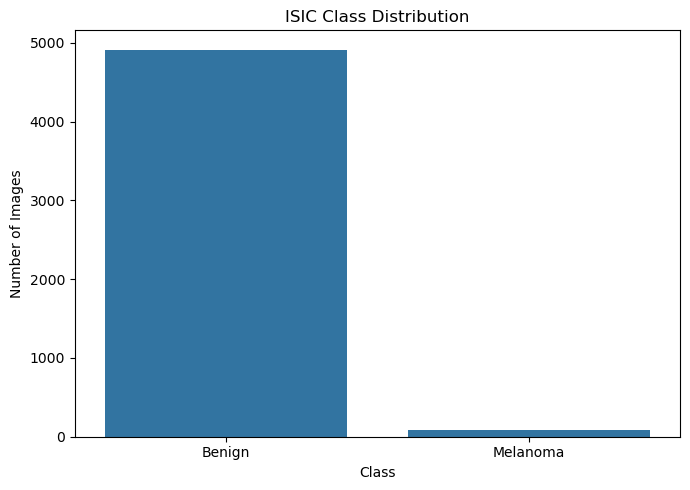

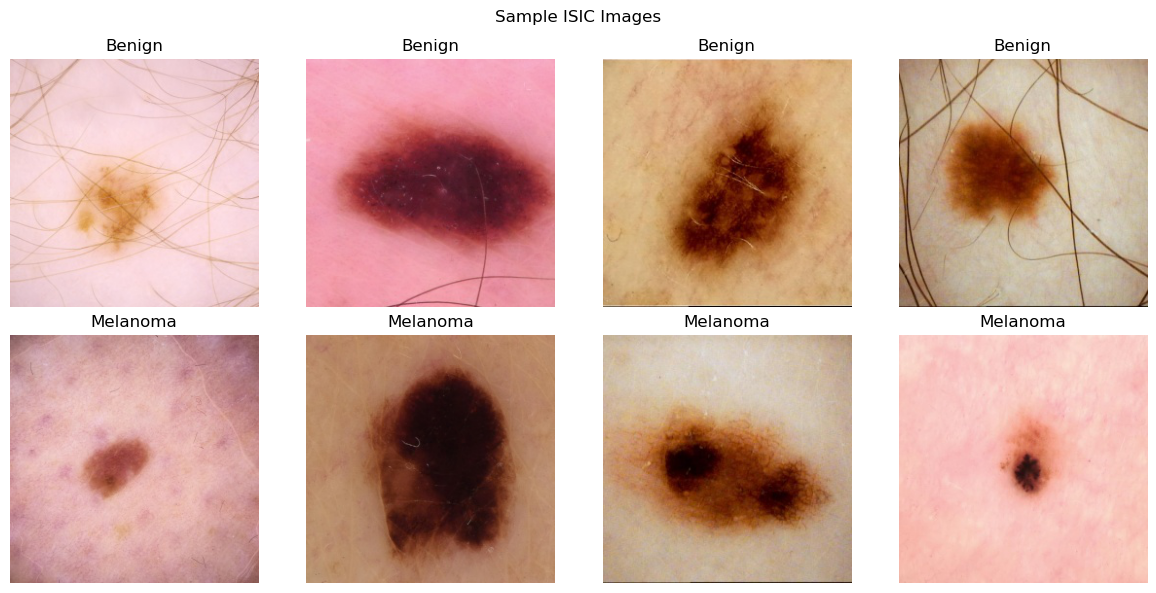

In [5]:
# ============================================================
# 4. EDA
# ============================================================

class_names = {0: "Benign", 1: "Melanoma"}

plt.figure(figsize=(7, 5))
counts = df["label"].map(class_names).value_counts()
sns.barplot(x=counts.index, y=counts.values)
plt.title("ISIC Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

# Show example images from both classes.
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, label in enumerate([0, 1]):
    samples = df[df["label"] == label].sample(
        n=min(4, len(df[df["label"] == label])),
        random_state=SEED
    )

    for col, (_, r) in enumerate(samples.iterrows()):
        img = Image.open(r["image_path"]).convert("RGB")
        axes[row, col].imshow(img)
        axes[row, col].set_title(class_names[label])
        axes[row, col].axis("off")

plt.suptitle("Sample ISIC Images")
plt.tight_layout()
plt.show()


## 5. Patient-Level Train / Validation / Test Split

When patient IDs are available, the split is performed by patient to reduce data leakage. If the downloaded CSV does not contain `patient_id`, the notebook falls back to a stratified image-level split and clearly reports that choice.

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

# ============================================================
# 5. SPLIT DATA
# ============================================================

if "patient_id" in df.columns and df["patient_id"].notna().all():
    # Patient-level split.
    patients = df["patient_id"].astype(str).unique()

    patient_labels = (
        df.groupby("patient_id")["label"]
        .max()
        .reindex(patients)
        .values
    )

    train_pat, temp_pat = train_test_split(
        patients,
        test_size=0.30,
        stratify=patient_labels,
        random_state=SEED
    )

    temp_labels = (
        df[df["patient_id"].astype(str).isin(temp_pat)]
        .groupby("patient_id")["label"]
        .max()
        .reindex(temp_pat)
        .values
    )

    val_pat, test_pat = train_test_split(
        temp_pat,
        test_size=0.50,
        stratify=temp_labels,
        random_state=SEED
    )

    patient_str = df["patient_id"].astype(str)
    train_df = df[patient_str.isin(train_pat)].copy()
    val_df = df[patient_str.isin(val_pat)].copy()
    test_df = df[patient_str.isin(test_pat)].copy()

    print("Split method: PATIENT-LEVEL")
else:
    train_df, temp_df = train_test_split(
        df, test_size=0.30, stratify=df["label"], random_state=SEED
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
    )

    print("Split method: STRATIFIED IMAGE-LEVEL")
    print("Warning: patient_id was unavailable, so patient-level leakage prevention was not possible.")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTrain distribution:")
print(train_df["label"].value_counts(normalize=True).sort_index())
print("\nValidation distribution:")
print(val_df["label"].value_counts(normalize=True).sort_index())
print("\nTest distribution:")
print(test_df["label"].value_counts(normalize=True).sort_index())


NameError: name 'df' is not defined

## 5b. Balance the Training Set

The ISIC dataset is heavily imbalanced (melanoma is the minority class). Class weighting alone reweights the loss, but the model still only *sees* a small number of unique melanoma images per epoch. This cell balances the **training set only** by oversampling the minority class (with replacement) up to the size of the majority class. Validation and test sets are left at their natural, real-world distribution so the evaluation metrics stay meaningful.

In [ ]:
# ============================================================
# 5b. BALANCE THE TRAINING SET (oversample the minority class)
# ============================================================

train_class_counts = train_df["label"].value_counts()
majority_count = int(train_class_counts.max())

print("Train distribution before balancing:")
print(train_class_counts.sort_index())

balanced_parts = []
for cls, group in train_df.groupby("label"):
    if len(group) < majority_count:
        group = group.sample(n=majority_count, replace=True, random_state=SEED)
    balanced_parts.append(group)

train_df = pd.concat(balanced_parts, ignore_index=True)
train_df = train_df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

print("\nTrain distribution after balancing:")
print(train_df["label"].value_counts().sort_index())
print(train_df["label"].value_counts(normalize=True).sort_index())


## 6. TensorFlow Image Pipeline

In [7]:
# ============================================================
# 6. DATA PIPELINE
# ============================================================

AUTOTUNE = tf.data.AUTOTUNE

augmenter = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="augmentation")

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    # NOTE (fix): kept in raw [0, 255] range on purpose. EfficientNetB0 already
    # contains its own internal rescaling layer and expects raw pixel values -
    # dividing by 255 here was silently feeding the pretrained CNN/RNN backbone
    # data on the wrong scale. The Vision Transformer now rescales itself
    # (see the ViT model cell below), so a single shared pipeline works for all
    # three models.
    return image, tf.cast(label, tf.float32)

def make_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).values
    labels = frame["label"].astype(np.float32).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.map(
            lambda x, y: (augmenter(x, training=True), y),
            num_parallel_calls=AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Datasets ready.")


Datasets ready.


## 7. Class Weights

Melanoma is the minority class in this dataset. Class weights make mistakes on the minority class matter more during training.

In [ ]:
# ============================================================
# 7. CLASS WEIGHTS
# ============================================================

class_counts = train_df["label"].value_counts().to_dict()
total = len(train_df)

class_weight = {
    int(cls): total / (2.0 * count)
    for cls, count in class_counts.items()
}

print("Class weights:", class_weight)


NameError: name 'train_df' is not defined

## 8. Common Training Callbacks

In [9]:
# ============================================================
# 8. CALLBACKS
# ============================================================

OUTPUT_DIR = Path("outputs")
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

def callbacks_for(name):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=2,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_auc",
            mode="max",
            factor=0.3,
            patience=1,
            min_lr=1e-6,
            verbose=1
        ),
        keras.callbacks.ModelCheckpoint(
            MODEL_DIR / f"{name}_best.keras",
            monitor="val_auc",
            mode="max",
            save_best_only=True,
            verbose=1
        )
    ]

def compile_model(model, lr=1e-4):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc")
        ]
    )
    return model


## 9. Model 1 — CNN (EfficientNetB0)

In [10]:
# ============================================================
# 9. CNN MODEL
# ============================================================

def build_cnn():
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3)
    )
    base.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="EfficientNetB0_CNN")
    return compile_model(model)

cnn_model = build_cnn()
cnn_model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "EfficientNetB0_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 10. Model 2 — RNN (CNN Features + Bidirectional LSTM)

An RNN is naturally designed for sequences. For image classification, this model first extracts a spatial feature map with a CNN and then treats the feature-map rows as a sequence for a Bidirectional LSTM.

In [11]:
# ============================================================
# 10. RNN MODEL
# ============================================================

def build_rnn():
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3)
    )
    base.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = base(inputs, training=False)       # feature map
    x = layers.Reshape((-1, x.shape[-1]))(x)
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=False))(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="CNN_BiLSTM_RNN")
    return compile_model(model)

rnn_model = build_rnn()
rnn_model.summary()


Model: "CNN_BiLSTM_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 49, 1280)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │     1,442,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,492,644 (20.95 MB)

 Trainable params: 1,443,073 (5.50 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 11. Model 3 — Vision Transformer (pretrained ViT-B/16, frozen)


In [12]:
# ============================================================
# 11. VISION TRANSFORMER MODEL (pretrained, frozen - fair comparison)
# ============================================================
# NOTE (fix): the original version of this cell trained a Vision Transformer
# completely FROM SCRATCH, while the CNN and RNN both used a frozen,
# ImageNet-PRETRAINED EfficientNetB0 backbone. ViTs lack the convolutional
# inductive bias CNNs have, so they typically need much more data/epochs (or
# pretraining) to perform well - training one from scratch here made the
# three-way comparison unfair (the Transformer was essentially set up to lose).
#
# This version uses a pretrained ViT-B/16 backbone (frozen, exactly like the
# other two models) so all three architectures are compared on the same
# footing: a frozen ImageNet-pretrained feature extractor + a small trainable
# classification head.

def build_vit():
    vit_backbone = vit.vit_b16(
        image_size=IMG_SIZE[0],
        activation="linear",
        pretrained=True,
        include_top=False,
        pretrained_top=False,
    )
    vit_backbone.trainable = False

    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    # ViT-B/16 preprocessing: rescale raw [0,255] pixels to [-1, 1].
    x = layers.Lambda(lambda t: (t / 127.5) - 1.0, name="vit_rescale")(inputs)
    x = vit_backbone(x, training=False)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs, name="Vision_Transformer")
    return compile_model(model, lr=1e-4)

vit_model = build_vit()
vit_model.summary()


Model: "Vision_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 768) │          0 │ input_layer_5[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 196, 64)   │     61,760 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 64)   │        128 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 64)   │          0 │ patch_encoder[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 196, 128)  │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 196, 64)   │      8,256 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 64)   │          0 │ add[0][0],        │
│                     │                   │            │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 64)   │          0 │ add_1[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 196, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 196, 128)  │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 196, 64)   │      8,256 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 196, 64)   │          0 │ add_2[0][0],      │
│                     │                   │            │ dense_6[0][0]   

 Total params: 128,897 (503.50 KB)

 Trainable params: 128,897 (503.50 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Train the Three Models

In [13]:
# ============================================================
# 12. TRAINING
# ============================================================

def train_model(model, name):
    print("\n" + "=" * 70)
    print("TRAINING:", name)
    print("=" * 70)

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        class_weight=class_weight,
        callbacks=callbacks_for(name),
        verbose=1
    )
    return history

histories = {}

histories["CNN"] = train_model(cnn_model, "cnn")
histories["RNN"] = train_model(rnn_model, "rnn")
histories["Transformer"] = train_model(vit_model, "transformer")



TRAINING: cnn
Epoch 1/3
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 894ms/step - accuracy: 0.5451 - auc: 0.4692 - loss: 0.7030
Epoch 1: val_auc improved from None to 0.50000, saving model to outputs\models\cnn_best.keras

Epoch 1: finished saving model to outputs\models\cnn_best.keras
112/112 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - accuracy: 0.5451 - auc: 0.4692 - loss: 0.7030 - val_accuracy: 0.9824 - val_auc: 0.5000 - val_loss: 0.6823 - learning_rate: 1.0000e-04
Epoch 2/3
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 724ms/step - accuracy: 0.5487 - auc: 0.4293 - loss: 0.7087
Epoch 2: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.

Epoch 2: val_auc did not improve from 0.50000
112/112 ━━━━━━━━━━━━━━━━━━━━ 97s 857ms/step - accuracy: 0.5487 - auc: 0.4293 - loss: 0.7087 - val_accuracy: 0.0176 - val_auc: 0.5000 - val_loss: 0.7087 - learning_rate: 1.0000e-04
Epoch 3/3
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 693ms/step - accuracy: 0.4358 - auc: 0.4461 - loss: 0.7069
Epoch 3: ReduceLROnPlateau reducing learn

## 13. Evaluation Functions

In [14]:
# ============================================================
# 13. EVALUATION
# ============================================================

def get_predictions(model, dataset):
    y_true = []
    y_prob = []

    for images, labels in dataset:
        probs = model.predict(images, verbose=0).ravel()
        y_prob.extend(probs)
        y_true.extend(labels.numpy())

    return np.asarray(y_true).astype(int), np.asarray(y_prob)


def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()
    return tn / (tn + fp) if (tn + fp) else 0.0


def evaluate_model(model, name):
    y_true, y_prob = get_predictions(model, test_ds)
    y_pred = (y_prob >= 0.5).astype(int)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Sensitivity / Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": specificity_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, y_prob)
    }

    print("\n", name)
    print(classification_report(
        y_true, y_pred,
        target_names=["Benign", "Melanoma"],
        zero_division=0
    ))

    return metrics, y_true, y_prob, y_pred


results = {}
predictions = {}

for name, model in [
    ("CNN", cnn_model),
    ("RNN", rnn_model),
    ("Transformer", vit_model)
]:
    metrics, y_true, y_prob, y_pred = evaluate_model(model, name)
    results[name] = metrics
    predictions[name] = (y_true, y_prob, y_pred)



 CNN
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       689
    Melanoma       0.00      0.00      0.00        13

    accuracy                           0.98       702
   macro avg       0.49      0.50      0.50       702
weighted avg       0.96      0.98      0.97       702


 RNN
              precision    recall  f1-score   support

      Benign       0.00      0.00      0.00       689
    Melanoma       0.02      1.00      0.04        13

    accuracy                           0.02       702
   macro avg       0.01      0.50      0.02       702
weighted avg       0.00      0.02      0.00       702


 Transformer
              precision    recall  f1-score   support

      Benign       0.98      0.84      0.91       689
    Melanoma       0.03      0.23      0.05        13

    accuracy                           0.83       702
   macro avg       0.51      0.54      0.48       702
weighted avg       0.97      0.83      0.89     

## 14. Model Comparison

In [15]:
# ============================================================
# 14. COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame(results).T.reset_index(drop=True)
comparison


,Model,Accuracy,Precision,Sensitivity / Recall,Specificity,F1,AUC-ROC
0,CNN,0.981481,0.0,0.0,1.0,0.0,0.604109
1,RNN,0.018519,0.018519,1.0,0.0,0.036364,0.315563
2,Transformer,0.833333,0.027273,0.230769,0.844702,0.04878,0.68974


## 15. Confusion Matrices

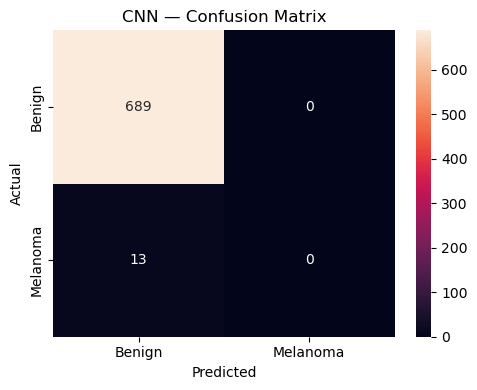

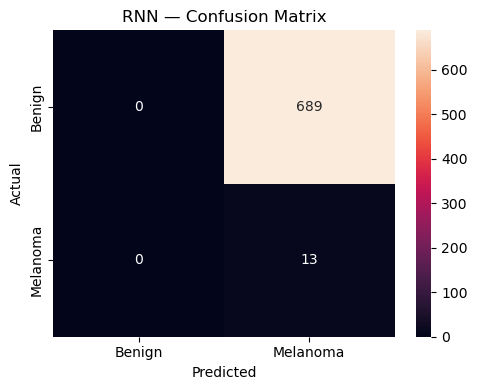

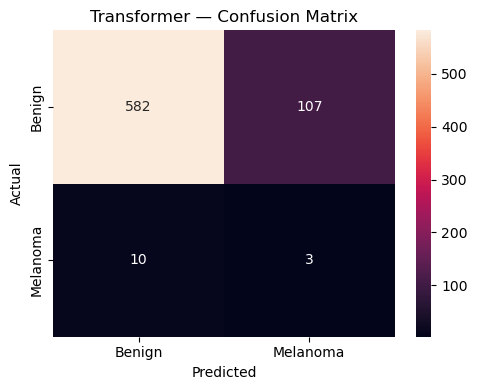

In [16]:
# ============================================================
# 15. CONFUSION MATRICES
# ============================================================

for name, (y_true, y_prob, y_pred) in predictions.items():
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Benign", "Melanoma"],
        yticklabels=["Benign", "Melanoma"]
    )
    plt.title(f"{name} — Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


## 16. ROC Curves

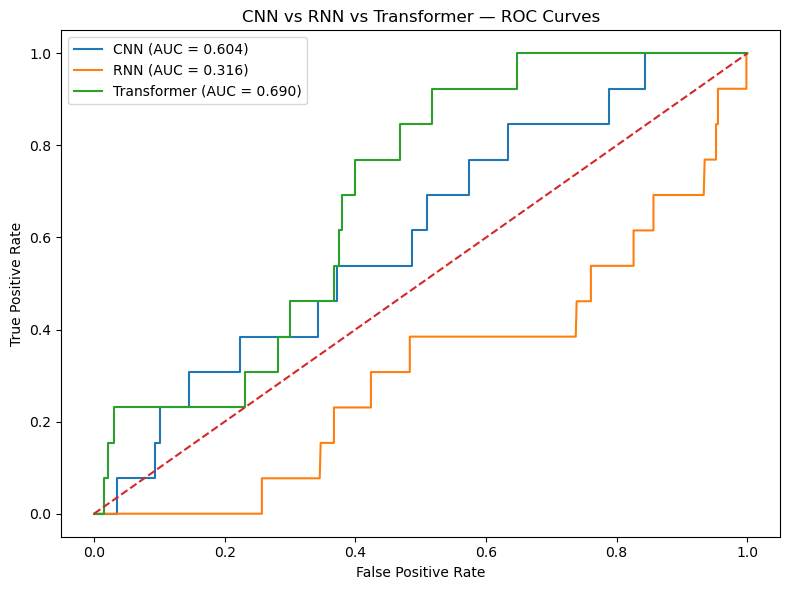

In [17]:
# ============================================================
# 16. ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, (y_true, y_prob, _) in predictions.items():
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN vs RNN vs Transformer — ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()


## 17. Training Curves

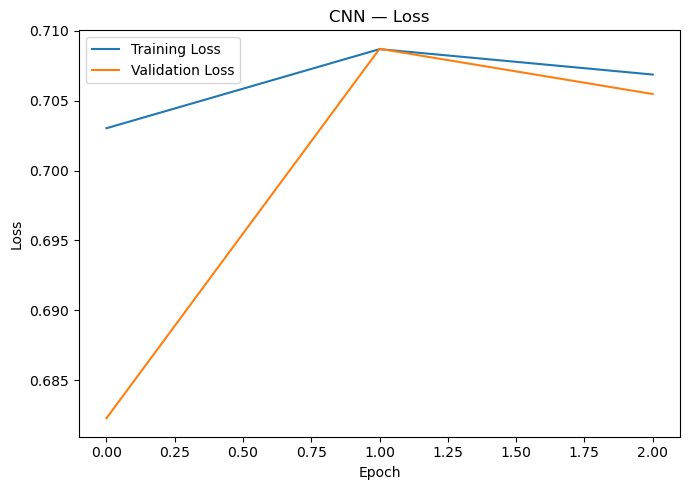

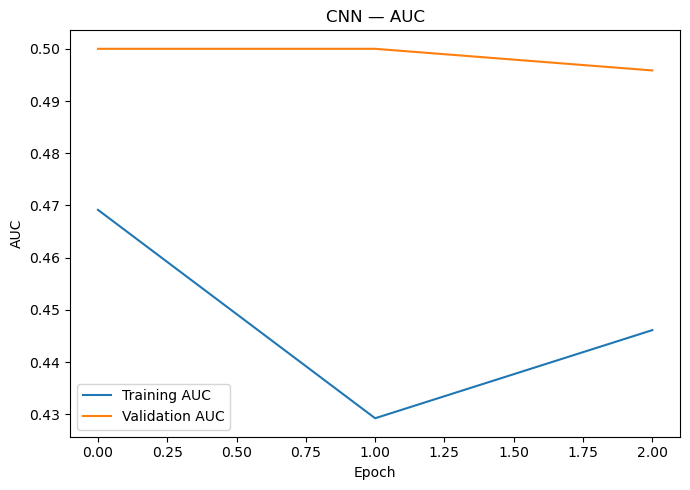

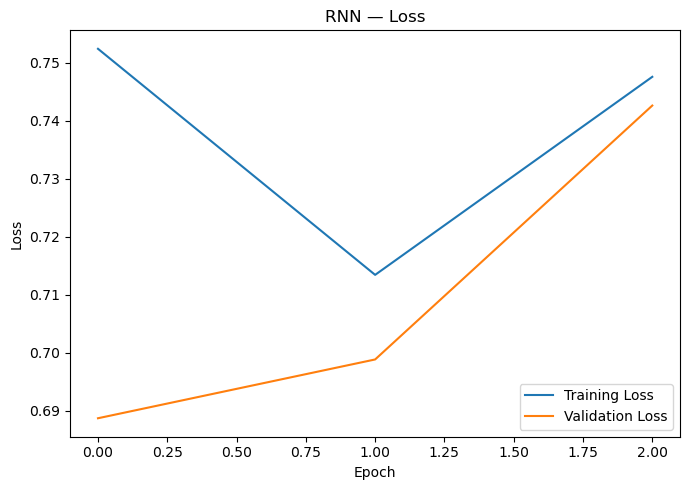

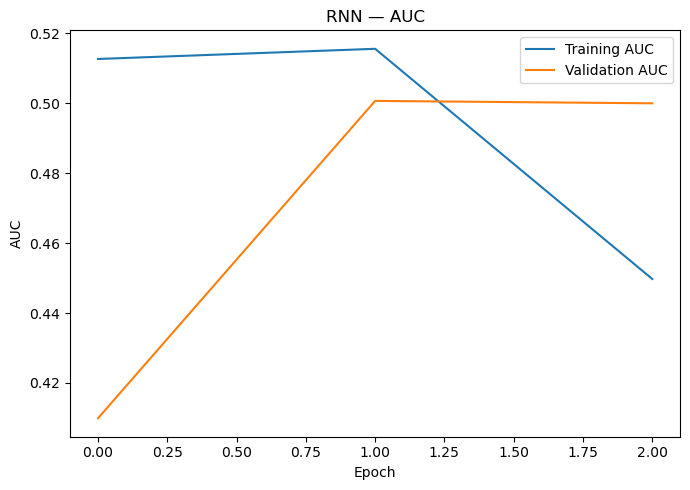

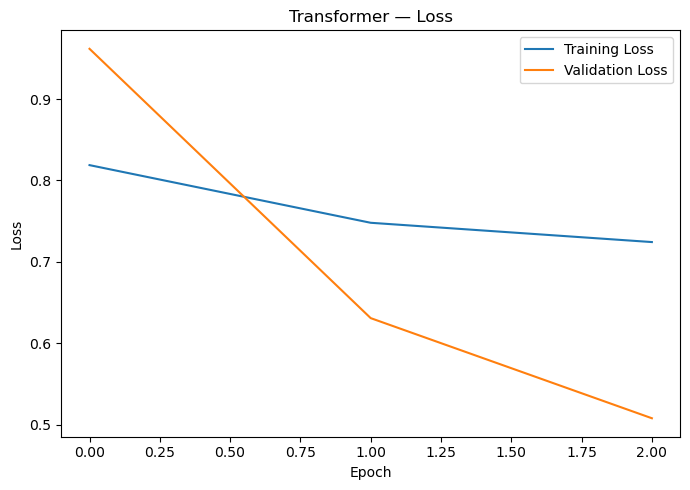

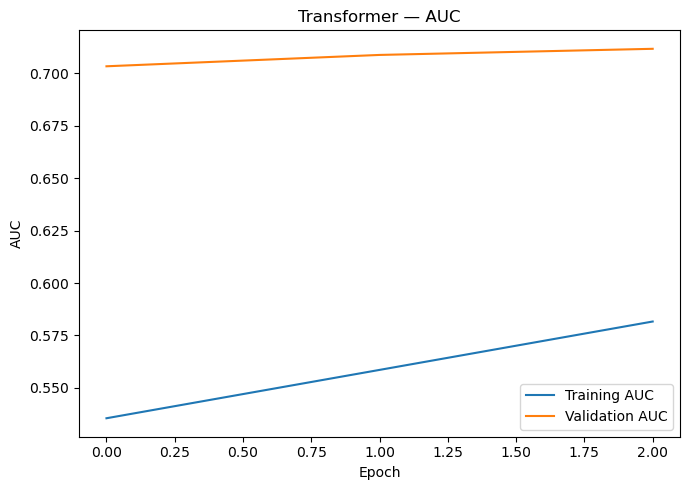

In [18]:
# ============================================================
# 17. TRAINING CURVES
# ============================================================

for name, history in histories.items():
    h = history.history

    plt.figure(figsize=(7, 5))
    plt.plot(h["loss"], label="Training Loss")
    plt.plot(h["val_loss"], label="Validation Loss")
    plt.title(f"{name} — Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(h["auc"], label="Training AUC")
    plt.plot(h["val_auc"], label="Validation AUC")
    plt.title(f"{name} — AUC")
    plt.xlabel("Epoch")
    plt.ylabel("AUC")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 18. Select and Save the Best Model

For this project, AUC-ROC is used as the primary comparison metric, while sensitivity is also important because missing a melanoma is a false negative.

In [19]:
# ============================================================
# 18. BEST MODEL + SAVE
# ============================================================

best_name = comparison.loc[
    comparison["AUC-ROC"].idxmax(), "Model"
]

model_map = {
    "CNN": cnn_model,
    "RNN": rnn_model,
    "Transformer": vit_model
}

best_model = model_map[best_name]

print(f"Best model by AUC-ROC: {best_name}")
print(comparison.sort_values("AUC-ROC", ascending=False))

best_model.save(MODEL_DIR / "best_skin_lesion_model.keras")
print("Saved:", MODEL_DIR / "best_skin_lesion_model.keras")


Best model by AUC-ROC: Transformer
         Model  Accuracy Precision Sensitivity / Recall Specificity        F1  \
2  Transformer  0.833333  0.027273             0.230769    0.844702   0.04878   
0          CNN  0.981481       0.0                  0.0         1.0       0.0   
1          RNN  0.018519  0.018519                  1.0         0.0  0.036364   

    AUC-ROC  
2   0.68974  
0  0.604109  
1  0.315563  
Saved: outputs\models\best_skin_lesion_model.keras


## 19. Single-Image Prediction

In [20]:
# ============================================================
# 19. SINGLE IMAGE PREDICTION
# ============================================================

def predict_single_image(image_path, model=best_model):
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = Image.open(image_path).convert("RGB")
    image_resized = image.resize(IMG_SIZE)

    arr = np.asarray(image_resized).astype("float32")  # raw [0,255] - matches training pipeline
    arr = np.expand_dims(arr, axis=0)

    probability = float(model.predict(arr, verbose=0)[0][0])

    predicted_class = "Melanoma" if probability >= 0.5 else "Benign"
    confidence = probability if probability >= 0.5 else 1 - probability

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.show()

    return predicted_class, confidence


# Example:
# prediction, confidence = predict_single_image("path/to/your/image.jpg")


## 20. Final Project Summary

### What we compared

| Model | Main idea |
|---|---|
| CNN | Learns local visual patterns such as edges, textures, colors and lesion structures |
| RNN | Uses CNN-extracted visual features as a sequence and processes them with a Bidirectional LSTM |
| Transformer | Splits the image into patches and uses self-attention to model relationships between patches |

### Important interpretation

Do **not** claim that one architecture is universally best. The final winner should be based on the metrics produced by **your actual experiment**.

For melanoma screening research, sensitivity/recall and AUC are especially important because a false negative means a melanoma was predicted as benign.

> **Educational disclaimer:** Results from this notebook must not be used to diagnose a real person.
